Le but de mon projet est de développer un modèle de Machine Learning capable d'estimer le prix d'un appartement à Paris à partir de ses caractéristiques, notamment sa surface, son arrondissement et son nombre de pièces. Pour cela, je vais utiliser des données réelles de ventes immobilières réalisées en 2025 et appliquer une méthode appelée régression linéaire. Je vais ensuite mesurer les erreurs de prédiction, comparer mon modèle à une méthode simple et déterminer si les résultats sont suffisamment fiables pour envisager une utilisation sur le site d'une agence immobilière.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliothèques importées avec succès.")

from google.colab import drive

drive.mount('/content/drive')

chemin = '/content/drive/MyDrive/ProjetML/ventes_appartements_paris_2025.csv'

df = pd.read_csv(chemin)

print("Données chargées :", df.shape)

df.head()

Bibliothèques importées avec succès.
Mounted at /content/drive
Données chargées : (29503, 9)


,id_vente,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
0,1,2025-11,16,34.0,33.50,2.0,1,0,400000.0
1,2,2025-09,15,25.0,19.56,2.0,2,1,178000.0
2,3,2025-06,16,235.0,235.47,7.0,1,5,2480000.0
3,4,2025-03,20,30.0,30.08,1.0,2,2,270000.0
4,5,2025-04,15,80.0,NaN,3.0,1,0,733475.0


2.Charger les donnees

Analyse des donnees

3.Analyse des données

In [ ]:
print("Dimensions du jeu de données :", df.shape)

print("\nStatistiques descriptives :")
display(df.describe().T)

print("\nNombre de doublons exacts :")
print(df.duplicated().sum())

Dimensions du jeu de données : (29503, 9)

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
id_vente,29503.0,14752.000000,8516.926832,1.0,7376.5000,14752.000,22127.5000,29503.0
arrondissement,29503.0,13.229367,4.851517,1.0,10.0000,14.000,17.0000,20.0
surface_m2,29501.0,52.858276,39.048357,1.0,28.0000,42.000,67.0000,1469.0
surface_carrez_m2,16576.0,49.155905,48.099364,1.1,25.0475,38.595,62.5025,3241.0
nb_pieces,29501.0,2.383004,1.277437,0.0,1.0000,2.000,3.0000,14.0
nb_lots,29503.0,1.659289,0.806580,0.0,1.0000,2.000,2.0000,20.0
nb_dependances,29503.0,0.879809,1.269627,0.0,0.0000,1.000,1.0000,164.0
prix_eur,29493.0,555391.470512,667462.465099,1.0,240000.0000,387000.000,646100.0000,44000000.0



Nombre de doublons exacts :
0


In [ ]:

# 1. Valeurs manquantes
print("Valeurs manquantes par colonne :")
display(df.isnull().sum().sort_values(ascending=False))

# 2. Types des colonnes
print("\nTypes des variables :")
display(df.dtypes)

# 3. Vérifier les valeurs uniques des colonnes
print("\nNombre de valeurs différentes par colonne :")
display(df.nunique().sort_values(ascending=False))

Valeurs manquantes par colonne :


,0
surface_carrez_m2,12927
prix_eur,10
nb_pieces,2
surface_m2,2
id_vente,0
mois,0
arrondissement,0
nb_lots,0
nb_dependances,0



Types des variables :


,0
id_vente,int64
mois,object
arrondissement,int64
surface_m2,float64
surface_carrez_m2,float64
nb_pieces,float64
nb_lots,int64
nb_dependances,int64
prix_eur,float64



Nombre de valeurs différentes par colonne :


,0
id_vente,29503
prix_eur,9640
surface_carrez_m2,7770
surface_m2,302
arrondissement,20
nb_lots,17
nb_pieces,15
nb_dependances,13
mois,12


L'analyse des valeurs manquantes révèle que la variable surface_carrez_m2 présente un nombre important de valeurs manquantes (12 927). Les variables surface_m2, nb_pieces et prix_eur comportent également quelques valeurs manquantes.

In [ ]:
print(df.columns.tolist())

['id_vente', 'mois', 'arrondissement', 'surface_m2', 'surface_carrez_m2', 'nb_pieces', 'nb_lots', 'nb_dependances', 'prix_eur']


In [ ]:
# Statistiques des variables utiles pour définir le périmètre
colonnes = [
    'arrondissement',
    'surface_m2',
    'surface_carrez_m2',
    'nb_pieces',
    'nb_lots',
    'nb_dependances',
    'prix_eur'
]

display(df[colonnes].describe().T)


,count,mean,std,min,25%,50%,75%,max
arrondissement,29503.0,13.229367,4.851517,1.0,10.0000,14.000,17.0000,20.0
surface_m2,29501.0,52.858276,39.048357,1.0,28.0000,42.000,67.0000,1469.0
surface_carrez_m2,16576.0,49.155905,48.099364,1.1,25.0475,38.595,62.5025,3241.0
nb_pieces,29501.0,2.383004,1.277437,0.0,1.0000,2.000,3.0000,14.0
nb_lots,29503.0,1.659289,0.806580,0.0,1.0000,2.000,2.0000,20.0
nb_dependances,29503.0,0.879809,1.269627,0.0,0.0000,1.000,1.0000,164.0
prix_eur,29493.0,555391.470512,667462.465099,1.0,240000.0000,387000.000,646100.0000,44000000.0


Nous avons déjà les nombres de valeurs manquantes : surface_m2 : 2, surface_carrez_m2 : 12 927, nb_pieces : 2 et prix_eur : 10.

### 3. Définition du périmètre

- **Surface Carrez :** cette variable comporte 12 927 valeurs manquantes. Je ne l'utiliserai pas comme variable principale du modèle, car son niveau de complétude est insuffisant par rapport à `surface_m2`.
- **Surface du logement :** je privilégierai `surface_m2`, qui ne présente que deux valeurs manquantes. Ces valeurs seront traitées dans le pipeline.
- **Prix de vente :** les 10 ventes dont le prix est manquant ne pourront pas servir à entraîner ni à évaluer le modèle, puisque le prix constitue la variable à prédire.
- **Nombre de pièces :** les deux valeurs manquantes seront traitées dans le pipeline, sans supprimer automatiquement les lignes concernées.

Les valeurs extrêmes et les incohérences seront examinées avant de fixer les autres règles d'exclusion.

In [ ]:
print("Surface supérieure à 200 m² :", (df["surface_m2"] > 200).sum())
print("Prix supérieur à 5 millions :", (df["prix_eur"] > 5_000_000).sum())
print("Nombre de pièces égal à 0 :", (df["nb_pieces"] == 0).sum())
print("Surface nulle ou négative :", (df["surface_m2"] <= 0).sum())
print("Prix nul ou négatif :", (df["prix_eur"] <= 0).sum())

Surface supérieure à 200 m² : 252
Prix supérieur à 5 millions : 84
Nombre de pièces égal à 0 : 47
Surface nulle ou négative : 0
Prix nul ou négatif : 0


In [ ]:
# Examiner la distribution des surfaces et des prix
print("Quantiles de surface :")
display(df["surface_m2"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
))

print("\nQuantiles des prix :")
display(df["prix_eur"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
))

print("\nRépartition du nombre de pièces :")
display(df["nb_pieces"].value_counts(dropna=False).sort_index())

Quantiles de surface :


,surface_m2
0.500,42.0
0.750,67.0
0.900,100.0
0.950,125.0
0.990,195.0
0.995,229.5



Quantiles des prix :


,prix_eur
0.500,387000.000
0.750,646100.000
0.900,1094972.000
0.950,1533579.800
0.990,2977560.000
0.995,3955883.452



Répartition du nombre de pièces :


,count
nb_pieces,
0.0,47
1.0,7952
2.0,10101
3.0,6429
4.0,3002
5.0,1310
6.0,434
7.0,162
8.0,44


In [ ]:
# Vérifier les appartements de très grande surface
df[df["surface_m2"] > 200][
    ["arrondissement", "surface_m2", "nb_pieces", "prix_eur"]
].head(10)



,arrondissement,surface_m2,nb_pieces,prix_eur
2,16,235.0,7.0,2480000.0
21,16,290.0,8.0,4157400.0
124,16,260.0,7.0,6011513.0
273,16,205.0,5.0,2810000.0
373,8,304.0,7.0,6150000.0
416,16,259.0,7.0,310000.0
428,7,230.0,7.0,5800000.0
512,7,236.0,6.0,4150.0
544,7,210.0,7.0,3295200.0
599,16,245.0,5.0,3700000.0


In [ ]:
# Vérifier les ventes à prix très élevé
df[df["prix_eur"] > 5_000_000][
    ["arrondissement", "surface_m2", "nb_pieces", "prix_eur"]
].head(10)

,arrondissement,surface_m2,nb_pieces,prix_eur
124,16,260.0,7.0,6011513.0
186,8,200.0,4.0,6100000.0
373,8,304.0,7.0,6150000.0
428,7,230.0,7.0,5800000.0
442,8,200.0,4.0,5300000.0
658,7,183.0,6.0,7590000.0
877,7,230.0,7.0,6350000.0
937,8,264.0,6.0,6250000.0
1551,16,210.0,7.0,5379531.5
2098,16,298.0,8.0,5900000.0


In [ ]:
# Examiner les ventes avec zéro pièce
df[df["nb_pieces"] == 0][
    ["arrondissement", "surface_m2", "nb_pieces", "prix_eur"]
].head(10)

,arrondissement,surface_m2,nb_pieces,prix_eur
662,18,12.0,0.0,85000.0
814,15,7.0,0.0,88000.0
1909,15,21.0,0.0,195000.0
3258,3,20.0,0.0,190000.0
3463,18,39.0,0.0,329100.0
4368,12,30.0,0.0,238628.0
5317,11,21.0,0.0,223500.0
6038,12,30.0,0.0,209000.0
6265,18,10.0,0.0,108850.0
6990,15,23.0,0.0,5000.0


### Analyse des distributions et des valeurs extrêmes

L’analyse des quantiles montre que la surface médiane des appartements est de 42 m² et que 99 % des surfaces sont inférieures ou égales à 195 m². Les surfaces très élevées sont donc rares, mais elles ne sont pas nécessairement erronées.

Le prix médian est de 387 000 €, tandis que 99 % des ventes ont un prix inférieur ou égal à environ 2,98 millions d’euros. La distribution des prix présente donc une dispersion importante, avec quelques ventes très coûteuses susceptibles d’influencer le modèle de régression linéaire.

Enfin, 47 ventes présentent un nombre de pièces égal à zéro et deux valeurs sont manquantes pour cette variable. Ces observations doivent être examinées avant de décider de leur traitement.

**Décision provisoire :** ne pas supprimer automatiquement les valeurs extrêmes. Vérifier leur cohérence et justifier toute exclusion en fonction de l’objectif du projet qui est d’estimer le prix d’un appartement ordinaire à Paris.

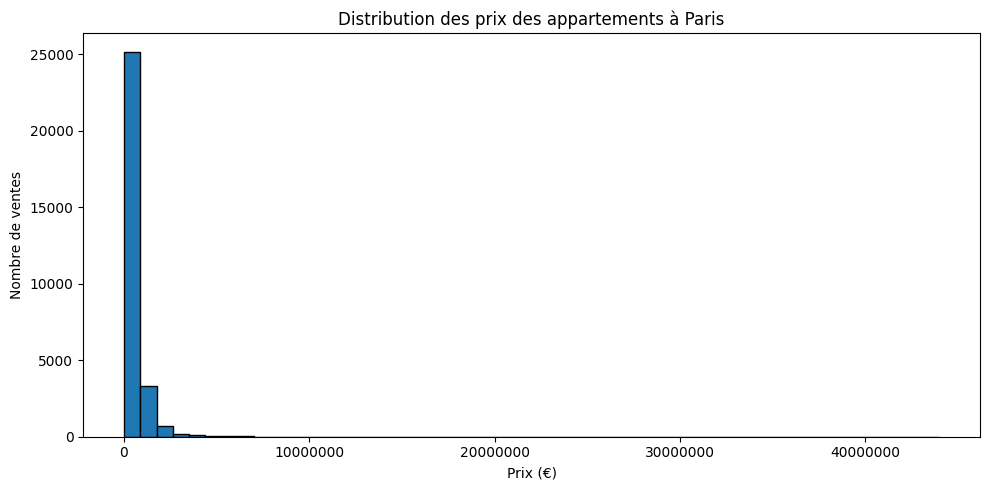

In [ ]:

# La distribution des prix
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["prix_eur"].dropna(), bins=50, edgecolor="black")
plt.title("Distribution des prix des appartements à Paris")
plt.xlabel("Prix (€)")
plt.ylabel("Nombre de ventes")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


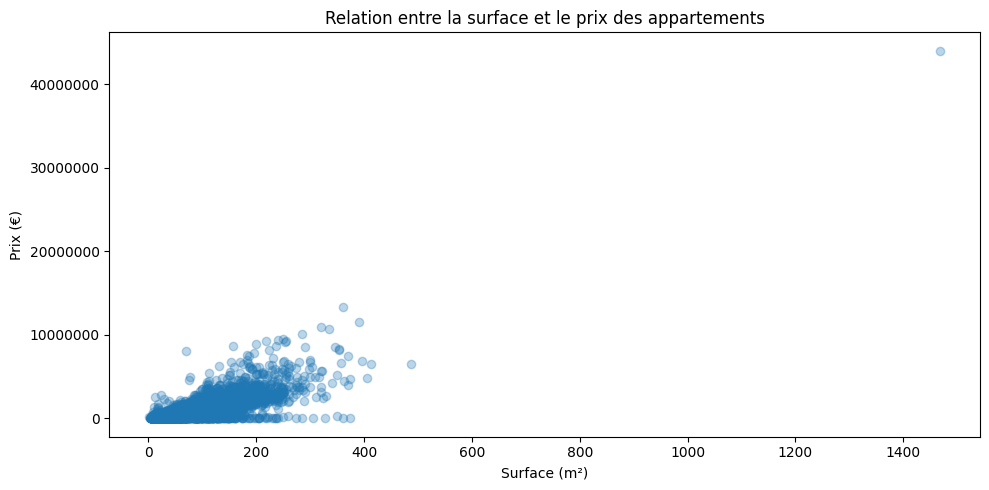

In [ ]:

#La surface en fonction du prix
plt.figure(figsize=(10, 5))
plt.scatter(df["surface_m2"], df["prix_eur"], alpha=0.3)
plt.title("Relation entre la surface et le prix des appartements")
plt.xlabel("Surface (m²)")
plt.ylabel("Prix (€)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


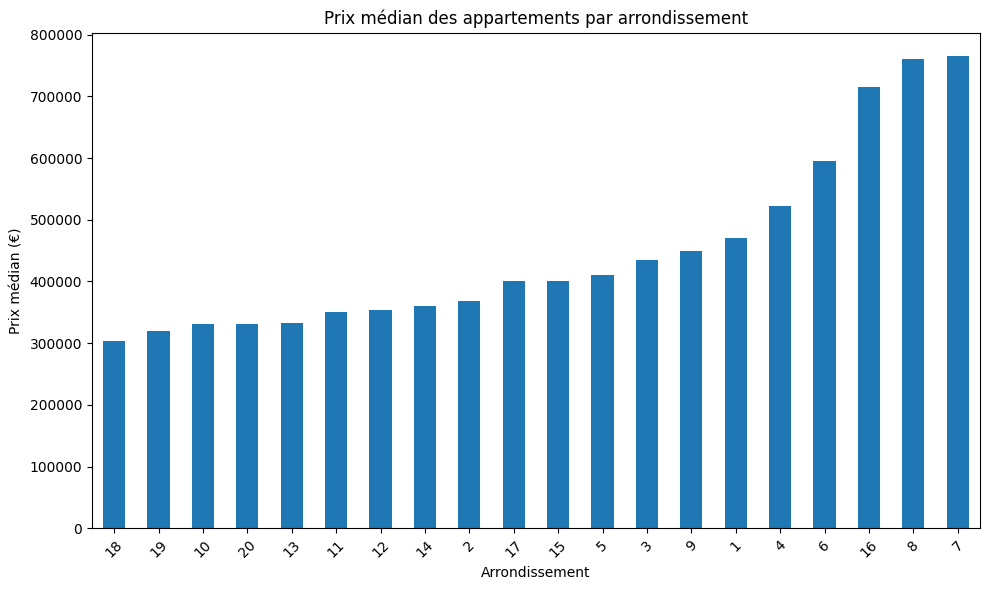

In [ ]:
# Le prix selon l’arrondissement
prix_par_arrondissement = (
    df.groupby("arrondissement")["prix_eur"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))
prix_par_arrondissement.plot(kind="bar")
plt.title("Prix médian des appartements par arrondissement")
plt.xlabel("Arrondissement")
plt.ylabel("Prix médian (€)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Repartition des donnees

In [ ]:

# Vérifier le nombre de prix manquants
print("Prix manquants :", df["prix_eur"].isna().sum())

# Retirer les lignes dont le prix est manquant
df = df.dropna(subset=["prix_eur"]).copy()

print("Nombre de lignes après nettoyage :", len(df))


Prix manquants : 10
Nombre de lignes après nettoyage : 29493


In [ ]:

from sklearn.model_selection import train_test_split

# Variable à prédire
y = df["prix_eur"]

# Variables explicatives
X = df.drop(columns=["prix_eur", "id_vente"])

# Séparation : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Taille des données d'entraînement :", X_train.shape)
print("Taille des données de test :", X_test.shape)
print("Taille de y_train :", y_train.shape)
print("Taille de y_test :", y_test.shape)


Taille des données d'entraînement : (23594, 7)
Taille des données de test : (5899, 7)
Taille de y_train : (23594,)
Taille de y_test : (5899,)


In [ ]:

from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor

# Baseline : prédire le prix médian de l'entraînement
baseline = DummyRegressor(strategy="median")

baseline.fit(X_train, y_train)

# Prédictions sur les données de test
y_pred_baseline = baseline.predict(X_test)

# Calcul de l'erreur absolue moyenne
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

print("Prix médian utilisé comme baseline :", baseline.constant_[0])
print("MAE de la baseline :", round(mae_baseline, 2), "€")


Prix médian utilisé comme baseline : [389015.81]
MAE de la baseline : 310108.08 €


- y_pred : les prix estimés par le modèle.
- y_test : les prix réellement observés.
- mae : l'écart absolu moyen entre les deux, exprimé en euros.

In [ ]:

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Variables numériques
numeric_features = [
    "surface_m2",
    "surface_carrez_m2",
    "nb_pieces",
    "nb_lots",
    "nb_dependances"
]

# Variables catégorielles
categorical_features = [
    "mois",
    "arrondissement"
]

# Traitement des variables numériques
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Traitement des variables catégorielles
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Regrouper les traitements
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Pipeline complet : traitements + régression linéaire
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

# Entraîner le modèle
model.fit(X_train, y_train)

# Prédire les prix du jeu de test
y_pred = model.predict(X_test)

# Calculer l'erreur
mae_model = mean_absolute_error(y_test, y_pred)

print("MAE de la baseline :", round(mae_baseline, 2), "€")
print("MAE de la régression linéaire :", round(mae_model, 2), "€")


MAE de la baseline : 310108.08 €
MAE de la régression linéaire : 165748.49 €


Résultats de la baseline et du premier modèle

La baseline, qui prédit systématiquement le prix médian des appartements du jeu d'entraînement, obtient une MAE de 310 108,08 €.

Le modèle de régression linéaire, qui exploite les caractéristiques des appartements, obtient une MAE de 165 748,49 € sur le jeu de test.

L'erreur absolue moyenne diminue ainsi d'environ 46,6 % par rapport à la baseline. Ce résultat indique que les caractéristiques sélectionnées apportent une information utile pour estimer le prix des appartements.

Cependant, une erreur moyenne d'environ 165 748 € reste importante. Il sera donc nécessaire de comparer plusieurs configurations du modèle et d'analyser ses erreurs avant de conclure sur ses performances.

In [ ]:
from sklearn.model_selection import KFold, cross_val_score
import pandas as pd

# Validation croisée à 5 plis
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Validation croisée préparée.")
print("Nombre de plis :", cv.get_n_splits())

Validation croisée préparée.
Nombre de plis : 5


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
import pandas as pd

# Colonnes utilisées dans chaque version
versions = {
    "V1 - Toutes les variables": numeric_features + categorical_features,

    "V2 - Sans surface Carrez": [
        c for c in numeric_features + categorical_features
        if c != "surface_carrez_m2"
    ],

    "V3 - Sans dépendances": [
        c for c in numeric_features + categorical_features
        if c != "nb_dependances"
    ],

    "V4 - Sans mois": [
        c for c in numeric_features + categorical_features
        if c != "mois"
    ]
}

resultats = []

for nom, colonnes in versions.items():

    # Séparer les variables numériques et catégorielles
    num_cols = [c for c in numeric_features if c in colonnes]
    cat_cols = [c for c in categorical_features if c in colonnes]

    # Construire un pipeline propre à cette version
    preprocessor_version = ColumnTransformer(transformers=[
        ("num", clone(numeric_transformer), num_cols),
        ("cat", clone(categorical_transformer), cat_cols)
    ])

    pipeline_version = Pipeline(steps=[
        ("preprocessor", preprocessor_version),
        ("regression", LinearRegression())
    ])

    # Évaluer sur les données d'entraînement uniquement
    scores = cross_val_score(
        pipeline_version,
        X_train[colonnes],
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    mae_moyenne = -scores.mean()
    mae_ecart_type = scores.std()

    resultats.append({
        "Version": nom,
        "MAE moyenne (€)": round(mae_moyenne, 2),
        "Écart-type (€)": round(mae_ecart_type, 2)
    })

tableau_resultats = pd.DataFrame(resultats)
tableau_resultats.sort_values("MAE moyenne (€)")

,Version,MAE moyenne (€),Écart-type (€)
2,V3 - Sans dépendances,174926.86,5800.51
1,V2 - Sans surface Carrez,176681.17,6842.21
3,V4 - Sans mois,176868.19,6758.70
0,V1 - Toutes les variables,176877.09,6848.36


In [ ]:
# Colonnes retenues pour la V3
colonnes_v3 = [
    c for c in numeric_features + categorical_features
    if c != "nb_dependances"
]

# Récupérer la meilleure version
meilleur_modele = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(transformers=[
        ("num", clone(numeric_transformer),
         [c for c in numeric_features if c in colonnes_v3]),
        ("cat", clone(categorical_transformer),
         [c for c in categorical_features if c in colonnes_v3])
    ])),
    ("regression", LinearRegression())
])

# Entraîner sur toutes les données d'entraînement
meilleur_modele.fit(X_train[colonnes_v3], y_train)

# Prédire les prix du jeu de test
y_pred_final = meilleur_modele.predict(X_test[colonnes_v3])

# Calculer la MAE finale
mae_finale = mean_absolute_error(y_test, y_pred_final)

print("MAE finale de la V3 :", round(mae_finale, 2), "€")

MAE finale de la V3 : 163658.86 €


In [ ]:
# Récupérer le préprocesseur et la régression linéaire
preprocessor_final = meilleur_modele.named_steps["preprocessor"]
regression_finale = meilleur_modele.named_steps["regression"]

# Récupérer les noms des variables après transformation
noms_variables = preprocessor_final.get_feature_names_out()

# Créer un tableau des coefficients
import pandas as pd

coefficients = pd.DataFrame({
    "Variable": noms_variables,
    "Coefficient": regression_finale.coef_
})

# Afficher les coefficients les plus positifs et les plus négatifs
print("Coefficients les plus positifs :")
display(coefficients.sort_values("Coefficient", ascending=False).head(10))

print("Coefficients les plus négatifs :")
display(coefficients.sort_values("Coefficient").head(10))

Coefficients les plus positifs :


,Variable,Coefficient
0,num__surface_m2,662423.991380
22,cat__arrondissement_7,308431.585505
21,cat__arrondissement_6,274241.528134
19,cat__arrondissement_4,142573.635657
23,cat__arrondissement_8,93069.689948
16,cat__arrondissement_1,74302.421537
20,cat__arrondissement_5,50536.627099
18,cat__arrondissement_3,27024.292703
12,cat__mois_2025-09,22839.278306
3,num__nb_lots,14228.810448


Coefficients les plus négatifs :


,Variable,Coefficient
2,num__nb_pieces,-151811.877167
34,cat__arrondissement_19,-133711.384228
35,cat__arrondissement_20,-132146.144986
28,cat__arrondissement_13,-109077.117628
27,cat__arrondissement_12,-97922.690802
30,cat__arrondissement_15,-80261.828140
32,cat__arrondissement_17,-79372.519872
25,cat__arrondissement_10,-79237.667981
29,cat__arrondissement_14,-68501.275330
33,cat__arrondissement_18,-64428.695672


In [ ]:
# Corrélation entre la surface et le nombre de pièces
print(
    df[["surface_m2", "nb_pieces"]]
    .corr()
)

            surface_m2  nb_pieces
surface_m2    1.000000   0.854224
nb_pieces     0.854224   1.000000


Interprétation des coefficients

L'analyse des coefficients du modèle permet d'identifier les variables associées aux variations du prix prédit.

La surface possède un coefficient positif de 662 423,99. Comme les variables numériques ont été normalisées, ce coefficient correspond à une augmentation d'un écart-type de la surface, toutes les autres variables étant maintenues constantes. Il indique une association positive entre la surface et le prix estimé.

La variable correspondant au 7e arrondissement possède un coefficient positif de 308 431,59. Cela signifie que, par rapport à l'arrondissement de référence, la présence dans le 7e arrondissement est associée à une augmentation du prix prédit, toutes les autres variables étant constantes.

Enfin, le nombre de pièces possède un coefficient négatif de -151 811,88. Ce résultat doit être interprété avec prudence, car le modèle prend simultanément en compte la surface et d'autres caractéristiques des logements. Les relations entre ces variables peuvent influencer le signe des coefficients.

Ces résultats décrivent les associations apprises par le modèle. Ils ne démontrent pas à eux seuls une relation de causalité.

In [ ]:
# Tableau de comparaison des prix réels et prédits
erreurs = X_test[colonnes_v3].copy()

erreurs["prix_reel"] = y_test
erreurs["prix_predit"] = y_pred_final

# Calculer l'erreur absolue
erreurs["erreur_absolue"] = (
    erreurs["prix_reel"] - erreurs["prix_predit"]
).abs()

# Afficher les 10 appartements les plus difficiles à estimer
display(
    erreurs.sort_values(
        "erreur_absolue",
        ascending=False
    ).head(10)
)

,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,mois,arrondissement,prix_reel,prix_predit,erreur_absolue
27815,285.0,NaN,10.0,7,2025-11,7,10114300.00,3.984842e+06,6.129458e+06
10327,390.0,377.08,8.0,6,2025-09,7,11500000.00,6.073552e+06,5.426448e+06
21917,188.0,NaN,7.0,3,2025-05,7,6252000.00,2.645743e+06,3.606257e+06
512,236.0,NaN,6.0,1,2025-07,7,4150.00,3.528632e+06,3.524482e+06
6529,24.0,NaN,6.0,2,2025-03,15,2760000.00,-3.927394e+05,3.152739e+06
6495,219.0,NaN,5.0,1,2025-09,19,21500.00,2.938788e+06,2.917288e+06
5664,150.0,143.40,4.0,1,2025-03,6,5229113.00,2.317560e+06,2.911553e+06
11632,145.0,NaN,4.0,2,2025-11,8,4764770.47,2.050523e+06,2.714247e+06
10064,300.0,NaN,7.0,2,2025-03,16,6727850.00,4.130518e+06,2.597332e+06
124,260.0,278.33,7.0,1,2025-04,16,6011513.00,3.500594e+06,2.510919e+06


In [ ]:
# Examiner les deux ventes aux prix très faibles
df.loc[
    df["prix_eur"].isin([4150, 21500]),
    [
        "mois",
        "arrondissement",
        "surface_m2",
        "surface_carrez_m2",
        "nb_pieces",
        "nb_lots",
        "nb_dependances",
        "prix_eur"
    ]
]

,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
512,2025-07,7,236.0,NaN,6.0,1,0,4150.0
6495,2025-09,19,219.0,NaN,5.0,1,1,21500.0


In [ ]:
# Examiner les ventes à prix très faibles
ventes_suspectes = df[
    (df["prix_eur"] < 50000) &
    (df["surface_m2"] > 0)
]

display(
    ventes_suspectes[
        [
            "mois",
            "arrondissement",
            "surface_m2",
            "surface_carrez_m2",
            "nb_pieces",
            "prix_eur"
        ]
    ].sort_values("prix_eur")
)

print("Nombre de ventes à examiner :", len(ventes_suspectes))

,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,prix_eur
92,2025-06,4,20.0,NaN,1.0,1.0
1227,2025-01,11,37.0,NaN,3.0,1.0
28415,2025-06,9,191.0,NaN,6.0,1.0
27034,2025-12,4,230.0,NaN,7.0,1.0
25726,2025-04,11,17.0,NaN,1.0,1.0
...,...,...,...,...,...,...
21434,2025-09,14,9.0,NaN,1.0,49000.0
18987,2025-11,17,5.0,NaN,1.0,49000.0
2041,2025-01,18,15.0,NaN,1.0,49000.0
16833,2025-09,11,5.0,7.54,1.0,49000.0


Nombre de ventes à examiner : 741


L'analyse des plus grandes erreurs de prédiction a permis d'identifier deux ventes particulièrement suspectes : un appartement de 236 m² vendu à 4 150 € et un appartement de 219 m² vendu à 21 500 €.

Ces prix semblent très faibles au regard des surfaces déclarées. Ces observations pourraient correspondre à des transactions particulières ou à des anomalies dans les données.

Avant de les exclure, il est nécessaire d'examiner les autres ventes à prix très faible et de vérifier leur cohérence avec l'objectif du projet, qui consiste à estimer le prix d'un appartement ordinaire à Paris.

In [ ]:

import joblib
import os

# Créer un dossier pour sauvegarder le modèle
os.makedirs("/content/drive/MyDrive/ProjetML", exist_ok=True)

# Sauvegarder le meilleur modèle
chemin_modele = "/content/drive/MyDrive/ProjetML/meilleur_modele_regression.pkl"

joblib.dump(meilleur_modele, chemin_modele)

print("Modèle sauvegardé avec succès !")
print("Emplacement :", chemin_modele)


Modèle sauvegardé avec succès !
Emplacement : /content/drive/MyDrive/ProjetML/meilleur_modele_regression.pkl


In [ ]:

# Recharger le modèle sauvegardé
modele_charge = joblib.load(chemin_modele)

print("Modèle rechargé avec succès !")


Modèle rechargé avec succès !


In [ ]:

# Prédictions avec le modèle rechargé
predictions_chargees = modele_charge.predict(X_test[colonnes_v3])

# Comparer les prédictions
print("Prédiction du modèle original :", y_pred_final[:5])
print("Prédiction du modèle rechargé :", predictions_chargees[:5])

# Vérifier que les résultats sont identiques
print(
    "Les prédictions sont identiques :",
    np.allclose(y_pred_final, predictions_chargees)
)


Prédiction du modèle original : [ 288166.98439492  339209.96994665  458677.77641521  988781.55028032
 1843267.98609609]
Prédiction du modèle rechargé : [ 288166.98439492  339209.96994665  458677.77641521  988781.55028032
 1843267.98609609]
Les prédictions sont identiques : True


Sauvegarde et rechargement du modèle

Après avoir sélectionné la version V3 de la régression linéaire, le pipeline complet a été sauvegardé au format .pkl à l'aide de la bibliothèque Joblib.

Le modèle sauvegardé comprend les étapes de prétraitement des données (gestion des valeurs manquantes, normalisation et encodage des variables catégorielles), ainsi que l'algorithme de régression linéaire entraîné.

Le modèle a ensuite été rechargé et testé sur les données de test. Les prédictions obtenues sont identiques à celles du modèle initial, ce qui confirme que la sauvegarde et le rechargement ont fonctionné correctement.

Estimer le prix des appartements A et B

In [ ]:
import pandas as pd

appartements = pd.DataFrame([
    {
        "surface_m2": 50,
        "surface_carrez_m2": 48,
        "nb_pieces": 2,
        "nb_lots": 1,
        "mois": "2025-06",
        "arrondissement": 11
    },
    {
        "surface_m2": 80,
        "surface_carrez_m2": 78,
        "nb_pieces": 3,
        "nb_lots": 1,
        "mois": "2025-06",
        "arrondissement": 15
    }
])

prix_estimes = meilleur_modele.predict(appartements[colonnes_v3])

print("Prix estimé de l'appartement A :", round(prix_estimes[0]), "€")
print("Prix estimé de l'appartement B :", round(prix_estimes[1]), "€")

Prix estimé de l'appartement A : 512413 €
Prix estimé de l'appartement B : 875737 €


Le modèle de régression linéaire a permis d'estimer le prix de deux appartements à Paris. L'appartement A est estimé à 512 413 €, tandis que l'appartement B est estimé à 875 737 €.

Le modèle attribue donc une valeur plus élevée à l'appartement B. Ces résultats illustrent la capacité du modèle à produire des estimations à partir des caractéristiques des biens immobiliers. Toutefois, ces prix restent indicatifs et doivent être interprétés en tenant compte des limites du modèle et des erreurs de prédiction.